# Task 01: World Population Distribution

Prodigy InfoTech Data Science Internship

Task: create a bar chart or histogram to show the distribution of a categorical or continuous variable.

Data: World Bank total population by country (1960-2024) and country metadata (region, income group). Source: https://data.worldbank.org/indicator/SP.POP.TOTL

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

os.makedirs("images", exist_ok=True)

COLOR = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def save(fig, name):
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

## Load data

The population file has 4 lines of metadata at the top, so I skip them.

In [2]:
url = "https://raw.githubusercontent.com/Prodigy-InfoTech/data-science-datasets/main/Task%201/"
pop = pd.read_csv(url + "API_SP.POP.TOTL_DS2_en_csv_v2_38144.csv", skiprows=4)
meta = pd.read_csv(url + "Metadata_Country_API_SP.POP.TOTL_DS2_en_csv_v2_38144.csv")

pop = pop.loc[:, ~pop.columns.str.startswith("Unnamed")]
meta = meta.loc[:, ~meta.columns.str.startswith("Unnamed")]

print(pop.shape, meta.shape)
pop.head()

(266, 69) (265, 5)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,107906.0,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107624.0
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130075728.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,607123269.0,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750503764.0,769294618.0
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,33831764.0,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106388440.0,108772632.0,...,418127845.0,429454743.0,440882906.0,452195915.0,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0,521764076.0
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,28157798.0,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0


## Cleaning

The file mixes countries with aggregates like World, Euro area and the income groups. These rows have no region in the metadata, so I use that to filter them out. Ethiopia and Venezuela have no income group, so I label them Unclassified.

In [3]:
df = pop.merge(meta[["Country Code", "Region", "IncomeGroup"]], on="Country Code", how="left")

print("Aggregate rows:", df["Region"].isna().sum())

countries = df[df["Region"].notna()].copy()
countries["IncomeGroup"] = countries["IncomeGroup"].fillna("Unclassified")
countries = countries.rename(columns={"2024": "pop_2024"})

print("Countries:", len(countries))
print("Missing 2024 values:", countries["pop_2024"].isna().sum())

Aggregate rows: 49
Countries: 217
Missing 2024 values: 0


Quick check: the countries should add up to roughly the World total.

In [4]:
world = df.loc[df["Country Code"] == "WLD", "2024"].item()
total = countries["pop_2024"].sum()

print(f"World row:        {world:,.0f}")
print(f"Sum of countries: {total:,.0f}")
print(f"Difference:       {(world - total) / world:.2%}")

World row:        8,142,056,446
Sum of countries: 8,118,643,547
Difference:       0.29%


Close enough (0.29%). The World total includes a few economies that aren't listed separately.

## Summary statistics (2024)

In [5]:
s = countries["pop_2024"]

print(s.describe().apply(lambda x: f"{x:,.0f}"))
print("Mean / median:", round(s.mean() / s.median(), 1))
print("Skewness:", round(s.skew(), 1))

count              217
mean        37,413,104
std        142,831,124
min              9,646
25%            831,087
50%          6,587,202
75%         27,032,412
max      1,450,935,791
Name: pop_2024, dtype: str
Mean / median: 5.7
Skewness: 8.8


The mean is about 5.7x the median, so the data is heavily right-skewed. A few very large countries pull the mean up.

## Histogram: population per country

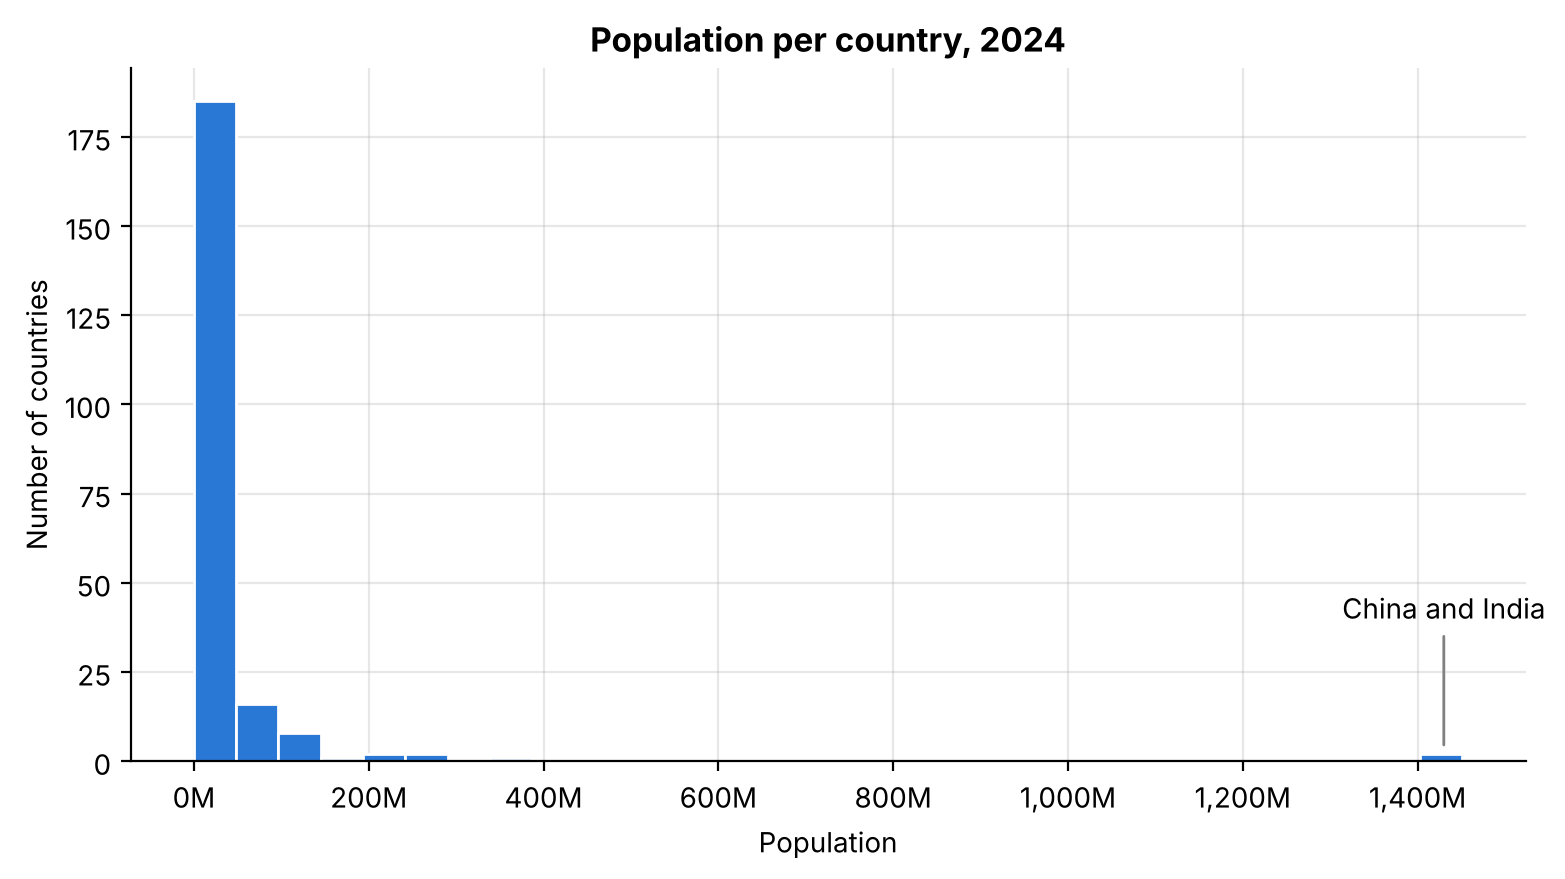

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(s, bins=30, color=COLOR, edgecolor="white")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"{x/1e6:,.0f}M"))
ax.annotate("China and India", xy=(1.43e9, 3), xytext=(1.43e9, 40), ha="center",
            arrowprops=dict(arrowstyle="-", color="gray"))
ax.set_title("Population per country, 2024")
ax.set_xlabel("Population")
ax.set_ylabel("Number of countries")
save(fig, "01_hist_linear")
plt.show()

Almost everything lands in the first bar because China and India stretch the axis. A log scale works better here.

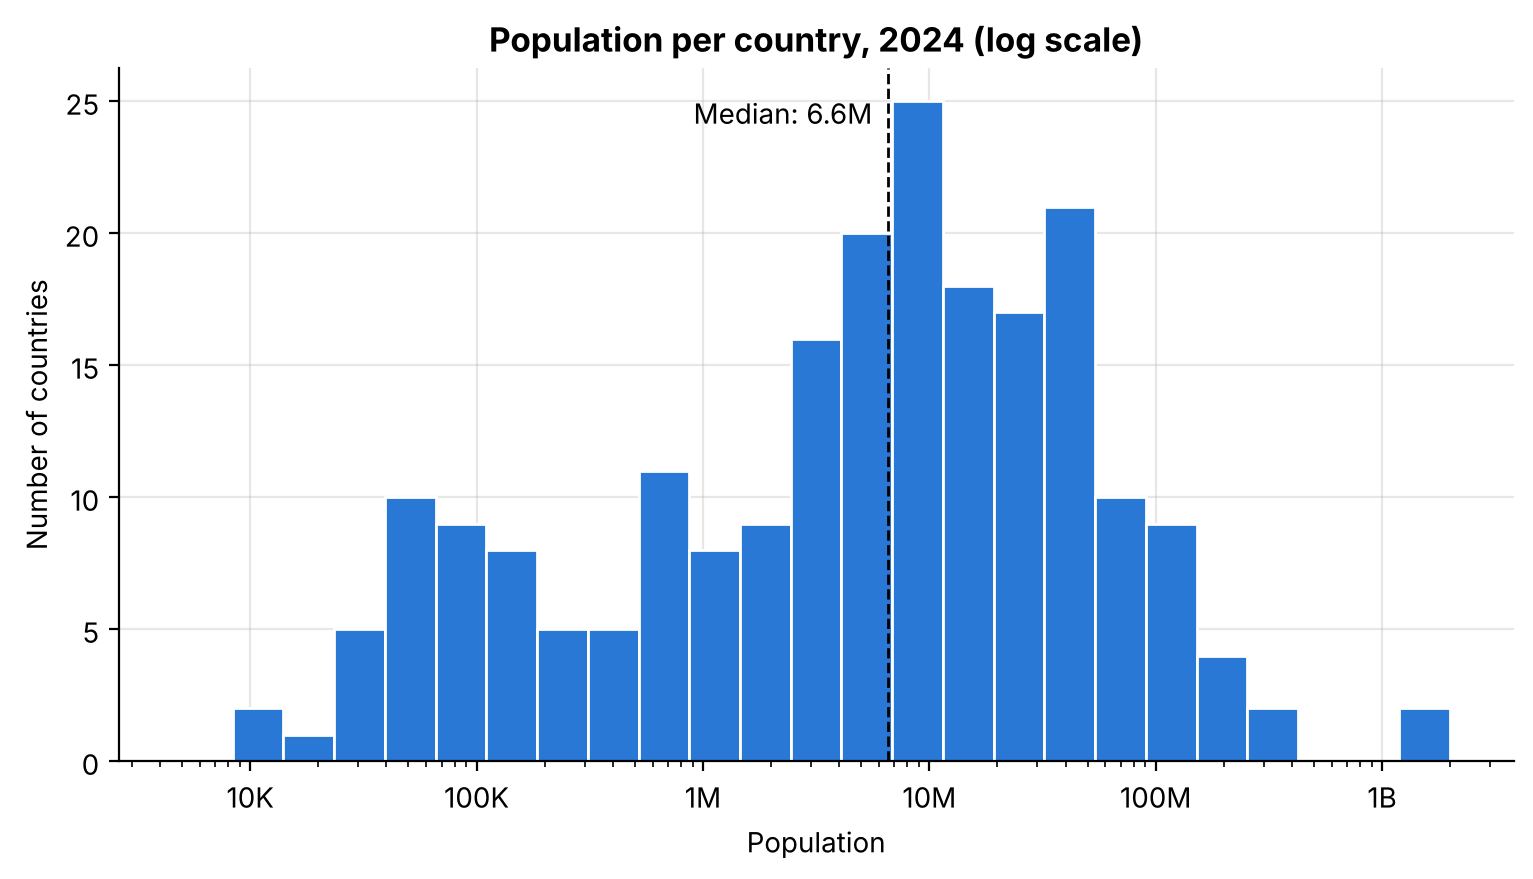

In [7]:
bins = np.logspace(np.log10(5_000), np.log10(2e9), 26)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(s, bins=bins, color=COLOR, edgecolor="white")
ax.set_xscale("log")
ax.set_xticks([1e4, 1e5, 1e6, 1e7, 1e8, 1e9])
ax.set_xticklabels(["10K", "100K", "1M", "10M", "100M", "1B"])
ax.axvline(s.median(), color="black", linestyle="--", linewidth=1)
ax.text(s.median() * 0.85, ax.get_ylim()[1] * 0.92, f"Median: {s.median()/1e6:.1f}M", ha="right")
ax.set_title("Population per country, 2024 (log scale)")
ax.set_xlabel("Population")
ax.set_ylabel("Number of countries")
save(fig, "02_hist_log")
plt.show()

In [8]:
bands = pd.cut(s, bins=[0, 1e5, 1e6, 1e7, 1e8, 1e10],
               labels=["<100K", "100K-1M", "1M-10M", "10M-100M", ">100M"])
bands.value_counts().sort_index()

pop_2024
<100K       23
100K-1M     34
1M-10M      66
10M-100M    78
>100M       16
Name: count, dtype: int64

On a log scale the distribution looks close to normal (log-normal). Most countries have 1M-100M people and only 16 have more than 100M.

## Bar charts: region and income group

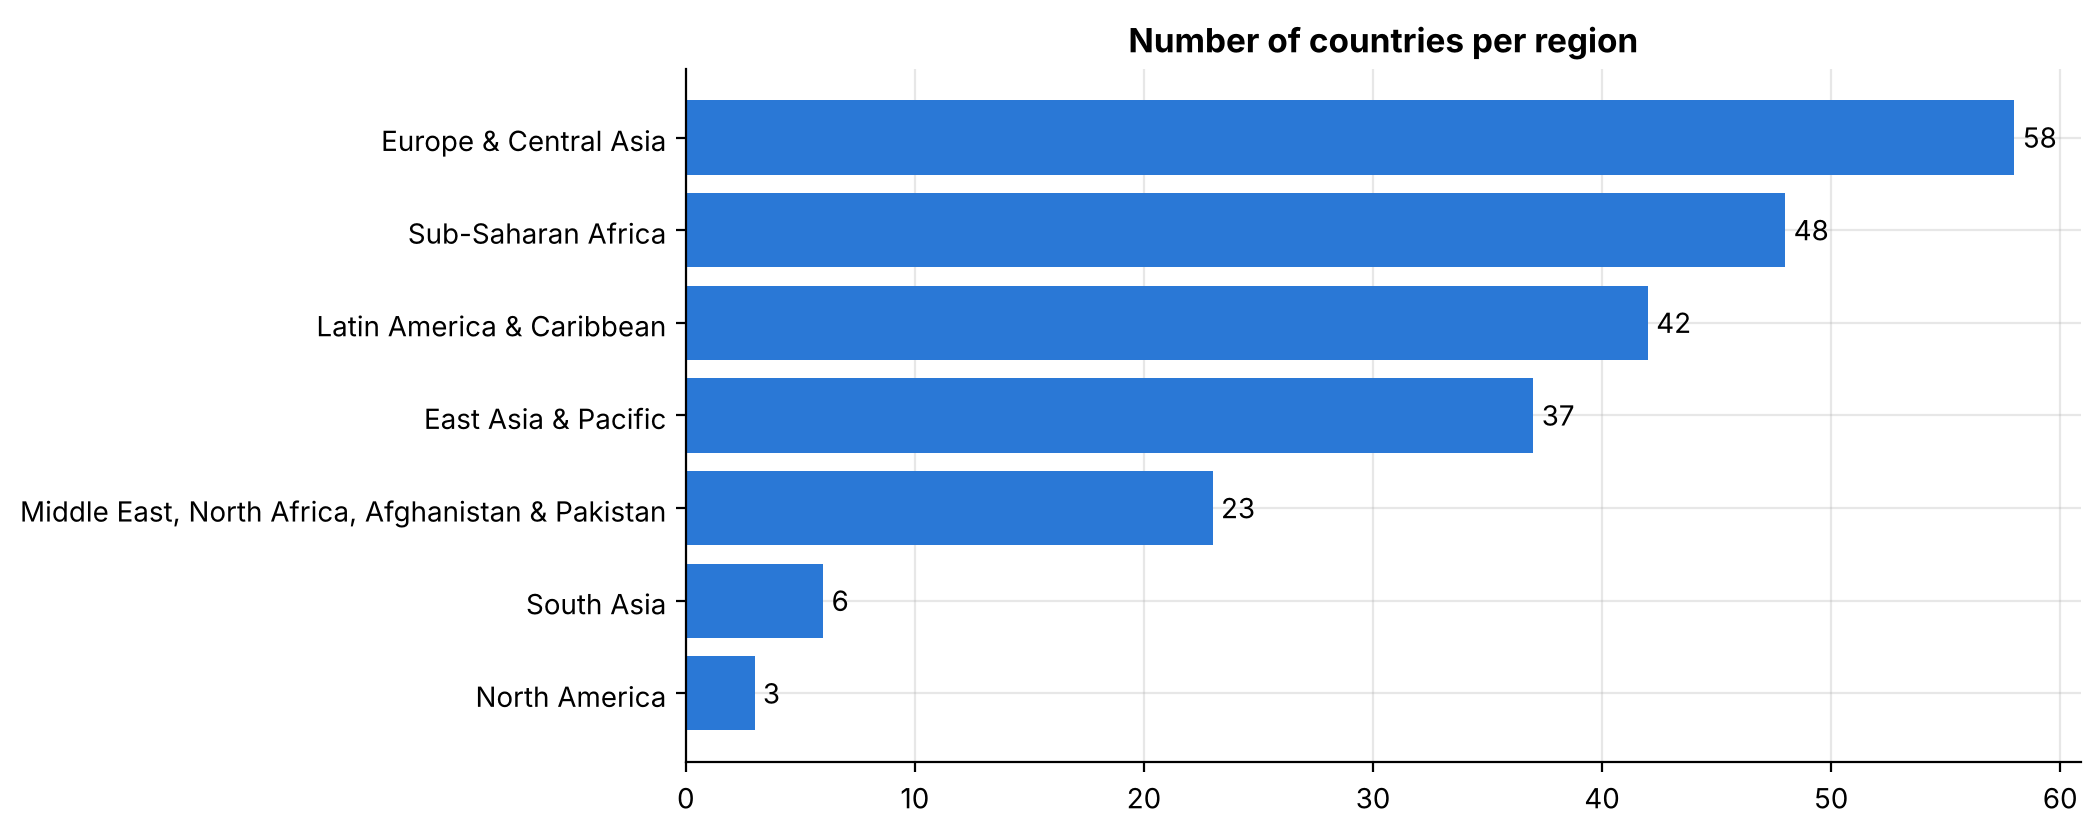

In [9]:
counts = countries["Region"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(counts.index, counts.values, color=COLOR)
ax.bar_label(bars, padding=3)
ax.set_title("Number of countries per region")
save(fig, "03_countries_per_region")
plt.show()

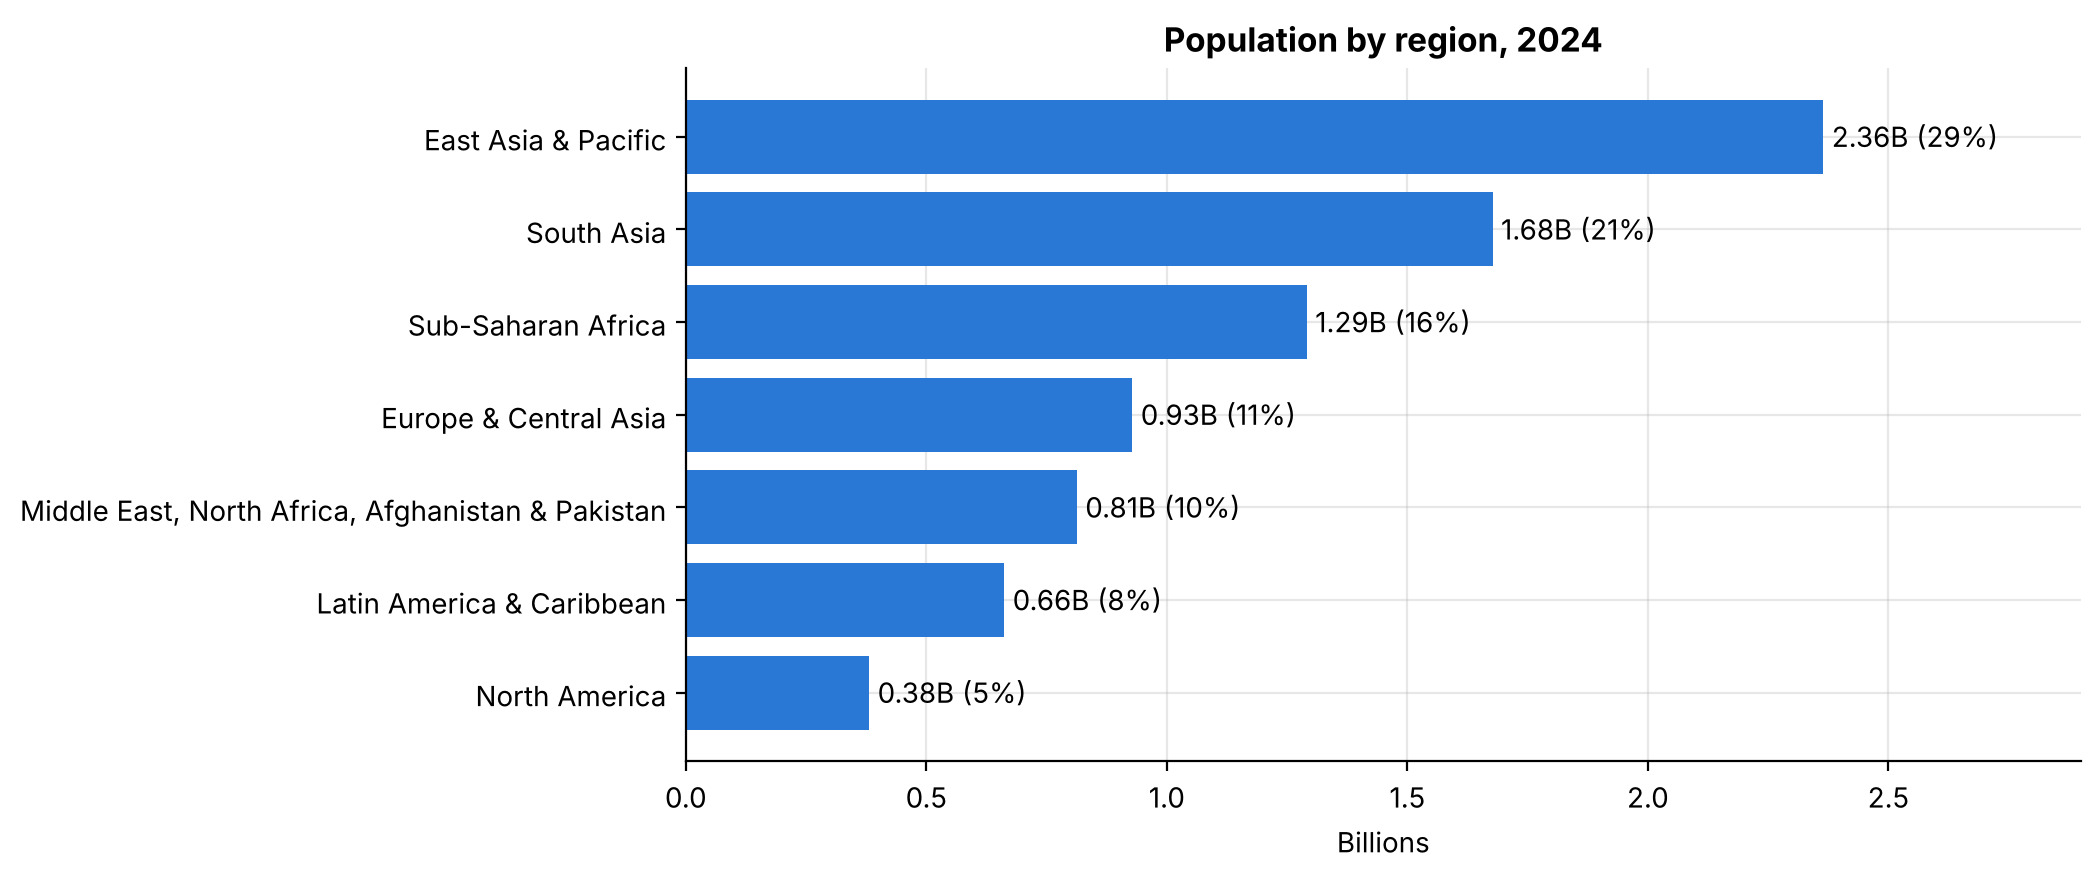

In [10]:
region_pop = countries.groupby("Region")["pop_2024"].sum().sort_values()
share = region_pop / region_pop.sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(region_pop.index, region_pop / 1e9, color=COLOR)
ax.bar_label(bars, labels=[f"{v/1e9:.2f}B ({p:.0%})" for v, p in zip(region_pop, share)], padding=3)
ax.set_xlim(0, 2.9)
ax.set_title("Population by region, 2024")
ax.set_xlabel("Billions")
save(fig, "04_population_per_region")
plt.show()

South Asia has only 6 countries but 21% of the world's population. Europe & Central Asia has 58 countries and 11%.

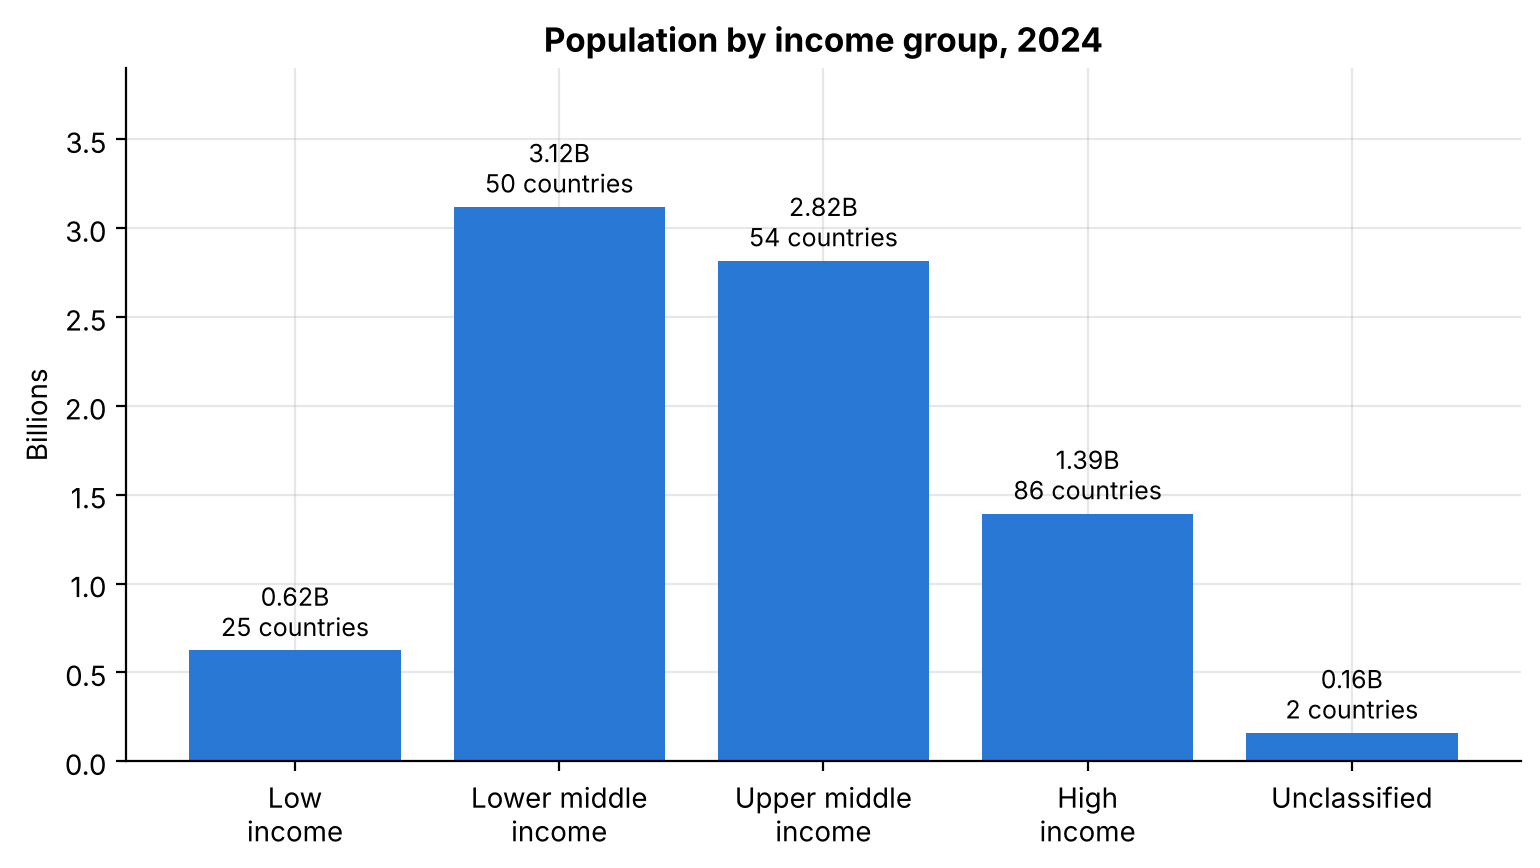

IncomeGroup
Low income             0.077
Lower middle income    0.384
Upper middle income    0.347
High income            0.172
Unclassified           0.020
Name: sum, dtype: float64


In [11]:
order = ["Low income", "Lower middle income", "Upper middle income", "High income", "Unclassified"]
income = countries.groupby("IncomeGroup")["pop_2024"].agg(["count", "sum"]).reindex(order)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar([x.replace(" income", "\nincome") for x in order], income["sum"] / 1e9, color=COLOR)
ax.bar_label(bars, labels=[f"{v/1e9:.2f}B\n{n} countries" for v, n in zip(income["sum"], income["count"])],
             padding=3, fontsize=9)
ax.set_ylim(0, 3.9)
ax.set_title("Population by income group, 2024")
ax.set_ylabel("Billions")
save(fig, "05_population_by_income")
plt.show()

print((income["sum"] / income["sum"].sum()).round(3))

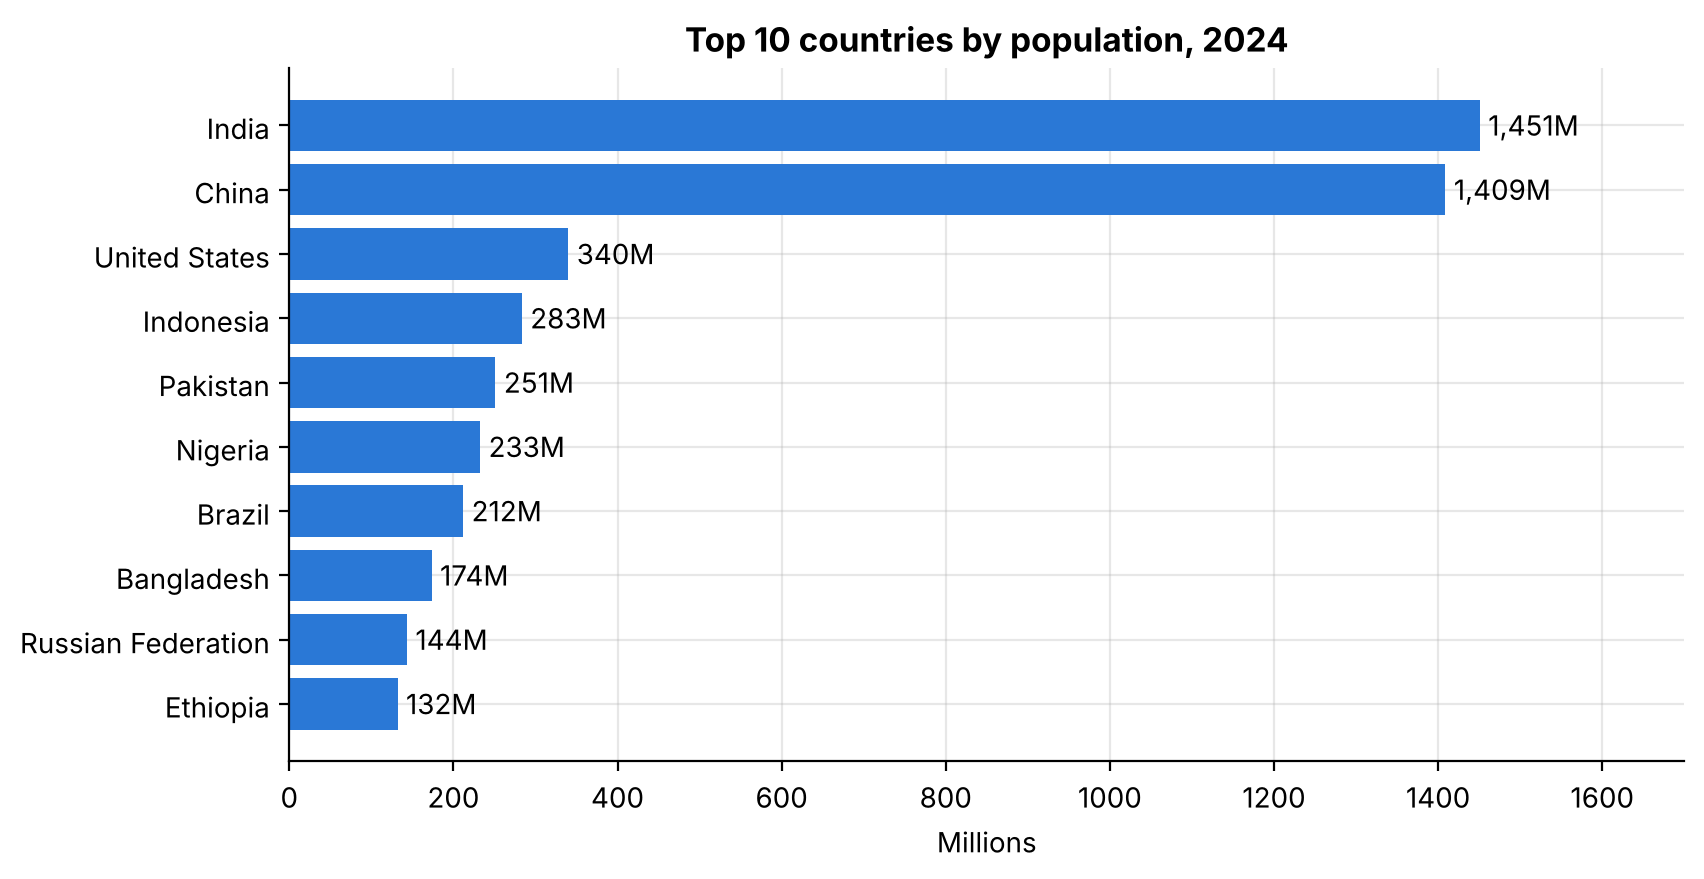

Top 10 share: 57%
India + China share: 35%


In [12]:
top10 = countries.nlargest(10, "pop_2024").sort_values("pop_2024")

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(top10["Country Name"], top10["pop_2024"] / 1e6, color=COLOR)
ax.bar_label(bars, labels=[f"{v/1e6:,.0f}M" for v in top10["pop_2024"]], padding=3)
ax.set_xlim(0, 1700)
ax.set_title("Top 10 countries by population, 2024")
ax.set_xlabel("Millions")
save(fig, "06_top10")
plt.show()

print(f"Top 10 share: {top10['pop_2024'].sum() / s.sum():.0%}")
print(f"India + China share: {top10['pop_2024'].tail(2).sum() / s.sum():.0%}")

## Findings

1. Country populations are very right-skewed (mean 37.4M vs median 6.6M), so the median is a better measure of a typical country.
2. On a log scale the distribution is roughly log-normal. Most countries have between 1M and 100M people.
3. The 10 largest countries hold 57% of the world's population. India and China alone hold 35%.
4. Number of countries doesn't match population. South Asia has 6 countries and 21% of the people, Europe & Central Asia has 58 countries and 11%.
5. 73% of people live in lower-middle or upper-middle income countries.

Note: the 217 entries include territories (e.g. Aruba, Greenland) as the World Bank defines them.